In [1]:
# Cell 1 — imports
from pathlib import Path

import numpy as np
from PIL import Image
from scipy import ndimage
import geopandas as gpd
import pandas as pd
from shapely.geometry import Point
import matplotlib.pyplot as plt

DATA_RAW = Path("../data/raw/Kegalle")
DATA_PROCESSED = Path("../data/processed")
DATA_RAW.mkdir(parents=True, exist_ok=True)


In [2]:
import fitz
from pathlib import Path

def pdf_to_png(pdf_path, out_prefix, dpi=300):
    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    doc = fitz.open(pdf_path)

    page = doc[0]

    zoom = dpi / 72
    matrix = fitz.Matrix(zoom, zoom)

    pix = page.get_pixmap(matrix=matrix, alpha=False)

    png_path = Path(f"{out_prefix}-1.png")
    pix.save(str(png_path))

    doc.close()

    return png_path

In [4]:
MAP_NAME = "Kegalle" 

In [5]:
pdf_path = DATA_RAW / f"{MAP_NAME.upper()}.pdf"

png_path = pdf_to_png(
    pdf_path,
    str(DATA_RAW / MAP_NAME)
)

im = Image.open(png_path).convert("RGB")
arr = np.array(im)

In [6]:
def find_frame_borders_kegalle(arr):
    h, w, _ = arr.shape

    # =========================================================
    # LEFT BORDER
    # Kegalle map begins very close to the left side
    # =========================================================
    x0, x1 = int(w * 0.02), int(w * 0.08)

    region = arr[
        int(h * 0.15):int(h * 0.85),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Kegalle left map border."
        )

    left = candidates[0] + x0


    # =========================================================
    # RIGHT BORDER
    # Map ends around 65% width, immediately before legend
    # =========================================================
    x0, x1 = int(w * 0.60), int(w * 0.68)

    region = arr[
        int(h * 0.15):int(h * 0.85),
        x0:x1,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=0)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Kegalle right map border."
        )

    # First strong vertical line in this narrow region
    right = candidates[0] + x0


    # =========================================================
    # TOP BORDER
    # Map starts below title/header
    # =========================================================
    y0, y1 = int(h * 0.06), int(h * 0.13)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Kegalle top map border."
        )

    top = candidates[0] + y0


    # =========================================================
    # BOTTOM BORDER
    # Map finishes above the red footer
    # =========================================================
    y0, y1 = int(h * 0.88), int(h * 0.96)

    region = arr[
        y0:y1,
        left:right,
        :
    ]

    gray = region.sum(axis=2)
    frac_dark = (gray < 300).mean(axis=1)

    candidates = np.where(frac_dark > 0.45)[0]

    if len(candidates) == 0:
        raise ValueError(
            "Could not detect Kegalle bottom map border."
        )

    bottom = candidates[-1] + y0


    return left, right, top, bottom


# =============================================================
# RUN FRAME DETECTION
# =============================================================

X_MIN, X_MAX, Y_MIN, Y_MAX = (
    find_frame_borders_kegalle(arr)
)

print(
    f"Kegalle frame: "
    f"x=[{X_MIN}, {X_MAX}], "
    f"y=[{Y_MIN}, {Y_MAX}]"
)

print(
    "Frame width:",
    X_MAX - X_MIN
)

print(
    "Frame height:",
    Y_MAX - Y_MIN
)

Kegalle frame: x=[170, 3191], y=[277, 3366]
Frame width: 3021
Frame height: 3089


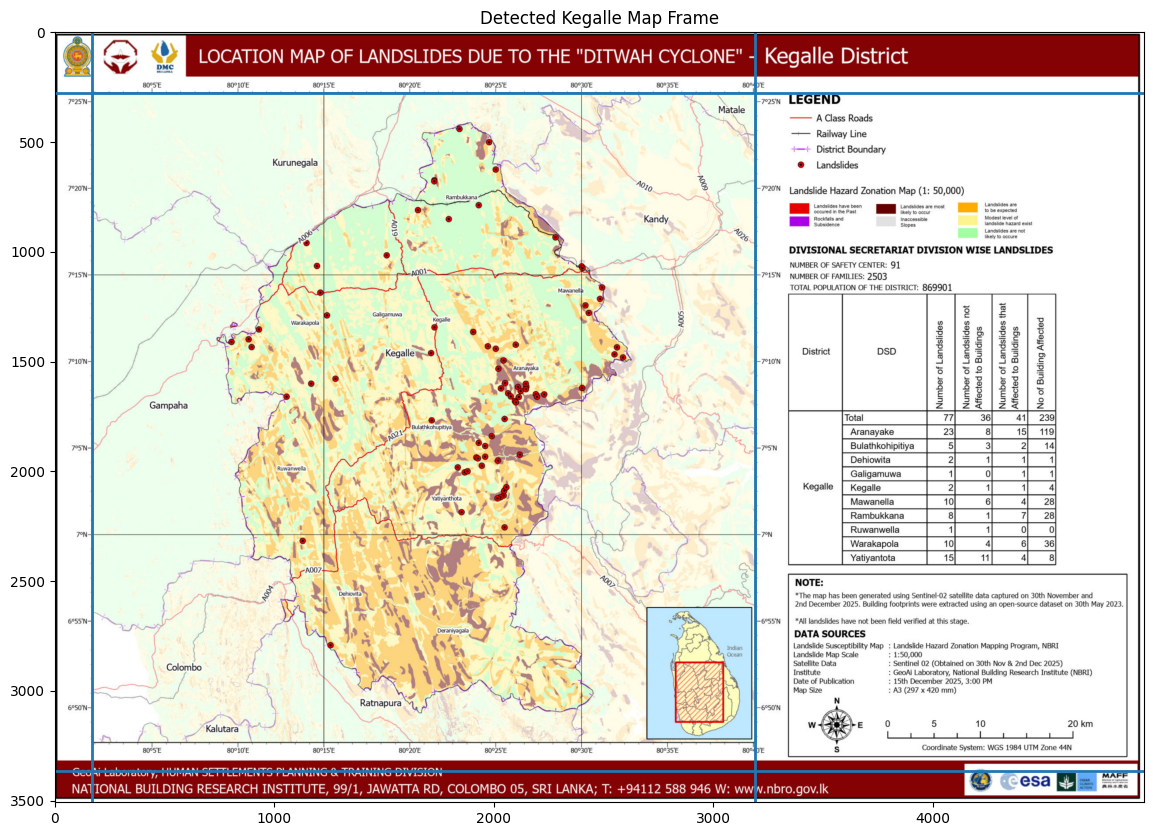

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

plt.imshow(arr)

plt.axvline(X_MIN, linewidth=2)
plt.axvline(X_MAX, linewidth=2)

plt.axhline(Y_MIN, linewidth=2)
plt.axhline(Y_MAX, linewidth=2)

plt.xlim(0, arr.shape[1])
plt.ylim(arr.shape[0], 0)

plt.title("Detected Kegalle Map Frame")
plt.show()

In [8]:
def zoom_crop(arr, x0, y0, x1, y1, scale=3, save_path="zoom_check.png"):
    crop = Image.fromarray(arr[y0:y1, x0:x1])
    crop = crop.resize(
        (crop.width * scale, crop.height * scale),
        Image.LANCZOS
    )
    crop.save(save_path)
    return save_path

In [9]:
# ============================================================
# Kegalle — Find Exact Graticule/Gridline Pixel Positions
# ============================================================

def find_vertical_gridline_kegalle(
    arr,
    x_search_start,
    x_search_end,
    y0,
    y1,
    dark_threshold=400,
    min_fraction=0.40
):
    """
    Find the exact X pixel position of a vertical longitude
    gridline inside a narrow search window.

    x_search_start and x_search_end should surround ONE
    expected longitude gridline only.
    """

    # Keep search inside detected Kegalle map frame
    x_search_start = max(x_search_start, X_MIN)
    x_search_end   = min(x_search_end, X_MAX)

    y0 = max(y0, Y_MIN)
    y1 = min(y1, Y_MAX)

    strip = arr[
        y0:y1,
        x_search_start:x_search_end,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each X position
    frac_dark = (
        gray < dark_threshold
    ).mean(axis=0)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Strongest vertical line
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(
        strongest + x_search_start
    )


def find_horizontal_gridline_kegalle(
    arr,
    y_search_start,
    y_search_end,
    x0,
    x1,
    dark_threshold=400,
    min_fraction=0.40
):
    """
    Find the exact Y pixel position of a horizontal latitude
    gridline inside a narrow search window.

    y_search_start and y_search_end should surround ONE
    expected latitude gridline only.
    """

    # Keep search inside detected Kegalle map frame
    y_search_start = max(
        y_search_start,
        Y_MIN
    )

    y_search_end = min(
        y_search_end,
        Y_MAX
    )

    x0 = max(x0, X_MIN)
    x1 = min(x1, X_MAX)

    strip = arr[
        y_search_start:y_search_end,
        x0:x1,
        :
    ]

    gray = strip.sum(axis=2)

    # Fraction of dark pixels for each Y position
    frac_dark = (
        gray < dark_threshold
    ).mean(axis=1)

    candidates = np.where(
        frac_dark > min_fraction
    )[0]

    if len(candidates) == 0:
        return None

    # Strongest horizontal line
    strongest = candidates[
        np.argmax(frac_dark[candidates])
    ]

    return int(
        strongest + y_search_start
    )

In [10]:
# ============================================================
# KEGALLE — IDENTIFY GRATICULE PIXEL POSITIONS
# Uses X_MIN, X_MAX, Y_MIN, Y_MAX obtained from
# find_frame_borders_kegalle(arr)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks


# ------------------------------------------------------------
# Avoid the outer black map frame
# ------------------------------------------------------------

margin = 30

x0 = X_MIN + margin
x1 = X_MAX - margin

y0 = Y_MIN + margin
y1 = Y_MAX - margin


# ------------------------------------------------------------
# Crop ONLY the Kegalle map area
# ------------------------------------------------------------

crop = arr[
    y0:y1,
    x0:x1,
    :
]


# ------------------------------------------------------------
# Convert to grayscale
# ------------------------------------------------------------

gray = crop.mean(axis=2)


# ------------------------------------------------------------
# Detect dark pixels
# ------------------------------------------------------------

dark = gray < 160


# ------------------------------------------------------------
# Calculate vertical/horizontal line strength
# ------------------------------------------------------------

vertical_score = dark.mean(axis=0)

horizontal_score = dark.mean(axis=1)


# ------------------------------------------------------------
# Find candidate LONGITUDE lines
#
# Kegalle map contains approximately:
#
# 80°05'E
# 80°10'E
# 80°15'E
# 80°20'E
# 80°25'E
# 80°30'E
# 80°35'E
# 80°40'E
#
# Therefore gridlines are relatively closely spaced.
# ------------------------------------------------------------

v_peaks, v_props = find_peaks(
    vertical_score,

    # Lower than Nuwara Eliya because Kegalle
    # longitude grid spacing is smaller
    distance=120,

    prominence=0.008
)


# ------------------------------------------------------------
# Find candidate LATITUDE lines
#
# Visible Kegalle latitude labels are approximately:
#
# 7°25'N
# 7°20'N
# 7°15'N
# 7°10'N
# 7°05'N
# 7°00'N
# 6°55'N
# 6°50'N
# ------------------------------------------------------------

h_peaks, h_props = find_peaks(
    horizontal_score,

    distance=120,

    prominence=0.008
)


# ------------------------------------------------------------
# Convert crop coordinates back to FULL IMAGE coordinates
# ------------------------------------------------------------

vertical_px = (
    v_peaks + x0
)

horizontal_px = (
    h_peaks + y0
)


print(
    "Possible longitude X pixels:"
)

print(vertical_px)


print(
    "\nPossible latitude Y pixels:"
)

print(horizontal_px)

Possible longitude X pixels:
[ 558  790  974 1094 1225 1370 1579 1821 2037 2398 2518 2695 2828 3047]

Possible latitude Y pixels:
[ 351  606  783  922 1106 1293 1413 1534 1668 1807 1947 2122 2289 2455
 2622 2744 2873 3059 3236]


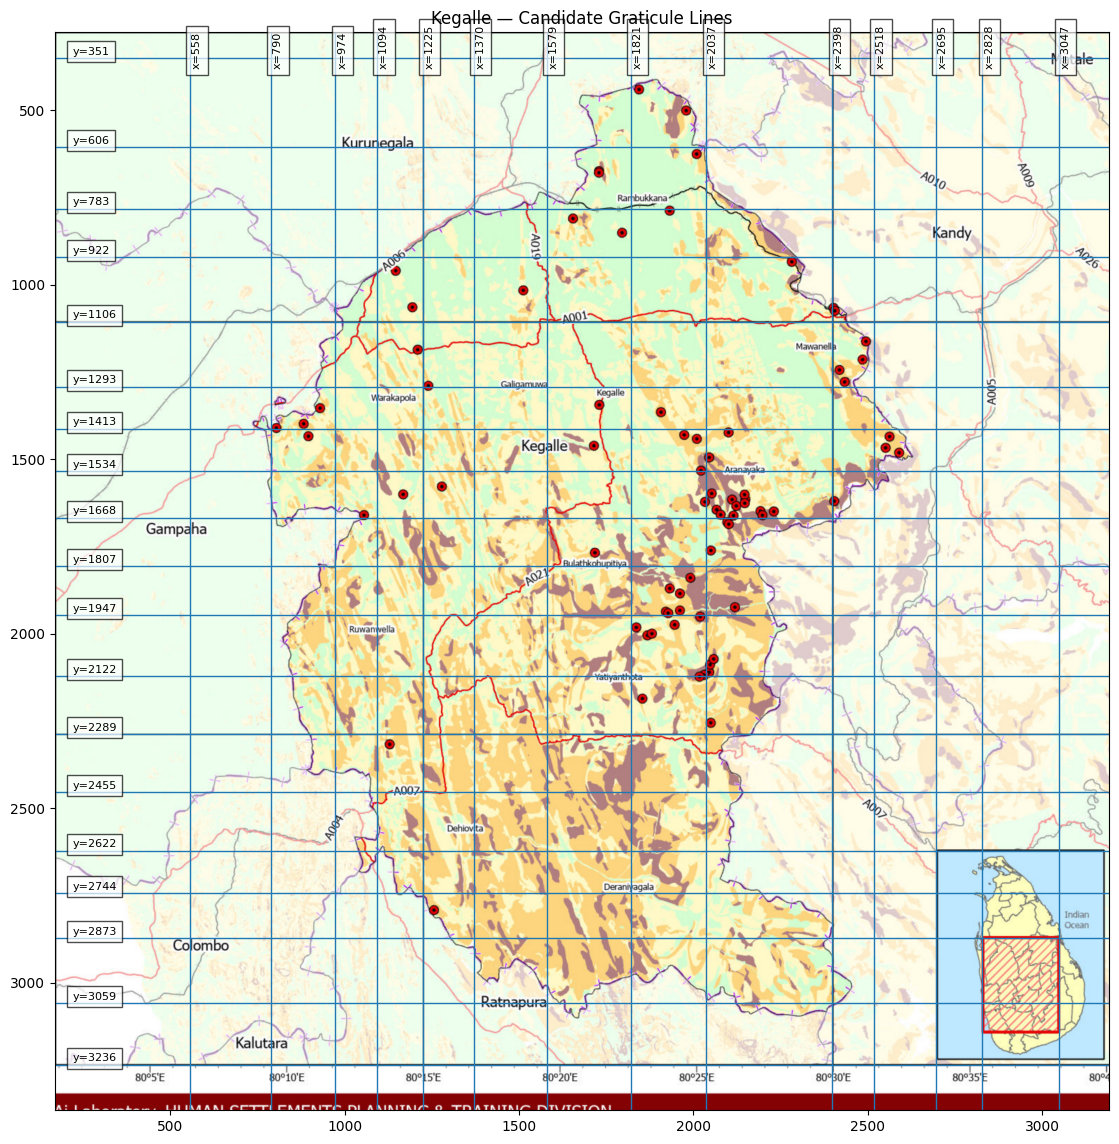

In [11]:
# ============================================================
# VISUAL CHECK OF KEGALLE GRIDLINE CANDIDATES
# ============================================================

plt.figure(
    figsize=(16, 14)
)

plt.imshow(arr)


# ------------------------------------------------------------
# Vertical longitude candidates
# ------------------------------------------------------------

for x in vertical_px:

    plt.axvline(
        x,
        linewidth=1
    )

    plt.text(
        x + 5,
        Y_MIN + 100,
        f"x={x}",
        rotation=90,
        fontsize=8,
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )


# ------------------------------------------------------------
# Horizontal latitude candidates
# ------------------------------------------------------------

for y in horizontal_px:

    plt.axhline(
        y,
        linewidth=1
    )

    plt.text(
        X_MIN + 50,
        y - 10,
        f"y={y}",
        fontsize=8,
        bbox=dict(
            facecolor="white",
            alpha=0.7
        )
    )


# ------------------------------------------------------------
# Display only detected map frame
# ------------------------------------------------------------

plt.xlim(
    X_MIN,
    X_MAX
)

plt.ylim(
    Y_MAX,
    Y_MIN
)

plt.title(
    "Kegalle — Candidate Graticule Lines"
)

plt.show()

In [12]:
# ============================================================
# KEGALLE — PIXEL TO GEOGRAPHIC COORDINATE CALIBRATION
# ============================================================

CALIBRATION = {

    # LONGITUDE
    
    "lon_a_deg": 80.166667,   # 80°10'E
    "lon_a_px": 790,

    "lon_b_deg": 80.583333,   # 80°35'E
    "lon_b_px": 2828,


    # LATITUDE

    "lat_a_deg": 7.333333,    # 7°20'N
    "lat_a_px": 351,

    "lat_b_deg": 6.916667,    # 6°55'N
    "lat_b_px": 3059
}


# ------------------------------------------------------------
# Calculate pixel scale
# ------------------------------------------------------------

px_per_deg_lon = (
    CALIBRATION["lon_b_px"]
    - CALIBRATION["lon_a_px"]
) / (
    CALIBRATION["lon_b_deg"]
    - CALIBRATION["lon_a_deg"]
)


px_per_deg_lat = (
    CALIBRATION["lat_b_px"]
    - CALIBRATION["lat_a_px"]
) / (
    CALIBRATION["lat_b_deg"]
    - CALIBRATION["lat_a_deg"]
)


# ------------------------------------------------------------
# Convert image pixel -> longitude / latitude
# ------------------------------------------------------------

def px_to_lonlat(x_full, y_full):

    lon = (
        CALIBRATION["lon_a_deg"]
        + (
            x_full
            - CALIBRATION["lon_a_px"]
        ) / px_per_deg_lon
    )

    lat = (
        CALIBRATION["lat_a_deg"]
        + (
            y_full
            - CALIBRATION["lat_a_px"]
        ) / px_per_deg_lat
    )

    return lon, lat


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

print(
    "Pixels per degree longitude:",
    px_per_deg_lon
)

print(
    "Pixels per degree latitude :",
    px_per_deg_lat
)

print(
    "Top-left corner:",
    px_to_lonlat(
        X_MIN,
        Y_MIN
    )
)

print(
    "Bottom-right corner:",
    px_to_lonlat(
        X_MAX,
        Y_MAX
    )
)

Pixels per degree longitude: 4891.207825932613
Pixels per degree latitude : -6499.210398736649
Top-left corner: (80.03990894308146, 7.344718998522895)
Bottom-right corner: (80.65754779784102, 6.869430492614476)


In [14]:
# ============================================================
# KEGALLE — SAMPLE LANDSLIDE LEGEND DOT COLOUR
# ============================================================

def sample_dot_color(
    arr,
    x0,
    y0,
    x1,
    y1
):
    region = arr[
        y0:y1,
        x0:x1
    ]

    r = region[:, :, 0].astype(int)
    g = region[:, :, 1].astype(int)
    b = region[:, :, 2].astype(int)

    # Red landslide symbol
    is_red = (
        (r > 150) &
        (g < 100) &
        (b < 100) &
        ((r - g) > 70) &
        ((r - b) > 70)
    )

    ys, xs = np.where(is_red)

    if len(ys) == 0:
        raise ValueError(
            "No red pixels found in Kegalle legend crop — "
            "adjust the legend region."
        )

    samples = region[
        ys,
        xs
    ]

    print(
        f"{len(ys)} red pixels found"
    )

    print(
        "Sample colours:",
        samples[:10]
    )

    print(
        "Median RGB:",
        np.median(samples, axis=0)
    )

    return samples, len(ys)

In [15]:
# Landslide dot detection — handles fused/overlapping clusters of dots.
#
# Roads/text vs. dot clusters are told apart with an EROSION test instead
# of aspect-ratio/solidity: shrink each red blob by a couple of pixels.
#   - A thin road or text stroke disappears completely under erosion.
#   - A cluster of overlapping dots still has a solid core left over,
#     no matter how large or irregularly shaped the cluster is.
# This lets large fused clusters through (which the old aspect/solidity/
# max-size filters were wrongly rejecting), while still discarding roads.
#
# Splitting still uses the two-pass median-area calibration: the number of
# points inside a blob = round(area / single_dot_area), found as separated
# peaks of a smoothed distance transform, capped at that expected count.

import numpy as np
from scipy import ndimage
from skimage.feature import peak_local_max
from skimage.measure import regionprops
from skimage.morphology import disk, binary_opening, binary_erosion


def _find_valid_blobs(
    arr, x_min, x_max, y_min, y_max,
    r_min, g_max, b_max, red_diff,
    min_area, erosion_radius, min_fill
):
    body = arr[y_min:y_max, x_min:x_max]
    r = body[:, :, 0].astype(np.int16)
    g = body[:, :, 1].astype(np.int16)
    b = body[:, :, 2].astype(np.int16)

    red_mask = (
        (r >= r_min) & (g <= g_max) & (b <= b_max) &
        ((r - g) >= red_diff) & ((r - b) >= red_diff)
    )
    red_clean = binary_opening(red_mask, footprint=disk(1))
    labeled, n = ndimage.label(red_clean, structure=np.ones((3, 3)))

    valid_regions = []
    for region in regionprops(labeled):
        area = region.area
        if area < min_area:
            continue

        minr, minc, maxr, maxc = region.bbox
        h, w = maxr - minr, maxc - minc
        fill_ratio = area / (w * h) if w and h else 0
        if fill_ratio < min_fill:
            continue  # too sparse to be a solid dot/cluster

        # Erosion test: thin roads/text vanish, round dot clusters survive.
        local = labeled[minr:maxr, minc:maxc] == region.label
        eroded = binary_erosion(local, footprint=disk(erosion_radius))
        if eroded.sum() == 0:
            continue  # thin line -> reject

        valid_regions.append(region)

    return red_mask, labeled, valid_regions


def detect_dots(
    arr,
    x_min, x_max, y_min, y_max,

    # Red colour
    r_min=150, g_max=100, b_max=100, red_diff=70,

    # Shape filters -- now just area floor + fill ratio + erosion survival
    min_area=35,
    min_fill=0.45,
    erosion_radius=2,

    # Splitting behaviour
    single_dot_area=None,   # None -> auto-calibrate from median blob area on this map
    split_threshold=1.4,    # a blob must be at least this many x single_dot_area before splitting
    min_distance=7,
    smooth_sigma=1.5
):
    red_mask, labeled, valid_regions = _find_valid_blobs(
        arr, x_min, x_max, y_min, y_max,
        r_min, g_max, b_max, red_diff,
        min_area, erosion_radius, min_fill
    )

    areas = np.array([reg.area for reg in valid_regions])

    if single_dot_area is None:
        # Median is robust to the occasional huge fused cluster skewing it,
        # since most blobs on the map are still isolated single dots.
        single_dot_area = float(np.median(areas))
        print(f"Auto-calibrated single_dot_area = {single_dot_area:.1f} px "
              f"(from {len(areas)} candidate blobs)")

    marker_mask = np.zeros(labeled.shape, dtype=bool)
    points_px = []

    for region in valid_regions:
        minr, minc, maxr, maxc = region.bbox
        area = region.area
        marker_mask[labeled == region.label] = True

        pad = 3
        r0 = max(minr - pad, 0)
        c0 = max(minc - pad, 0)
        r1 = min(maxr + pad, labeled.shape[0])
        c1 = min(maxc + pad, labeled.shape[1])

        local_mask = labeled[r0:r1, c0:c1] == region.label
        local_dist = ndimage.distance_transform_edt(local_mask)
        if smooth_sigma > 0:
            local_dist = ndimage.gaussian_filter(local_dist, sigma=smooth_sigma)

        if area < single_dot_area * split_threshold:
            expected_n = 1
        else:
            expected_n = max(1, round(area / single_dot_area))

        if expected_n == 1:
            cy, cx = np.unravel_index(np.argmax(local_dist), local_dist.shape)
            points_px.append((cx + c0 + x_min, cy + r0 + y_min))
        else:
            coords = peak_local_max(
                local_dist,
                min_distance=min_distance,
                labels=local_mask,
                num_peaks=expected_n,
                exclude_border=False
            )
            if len(coords) == 0:
                cy, cx = region.centroid
                points_px.append((cx + x_min, cy + y_min))
            else:
                for cy, cx in coords:
                    points_px.append((cx + c0 + x_min, cy + r0 + y_min))

    return points_px, red_mask, marker_mask, single_dot_area


In [17]:
import numpy as np


def remove_duplicate_points(points_px, duplicate_radius=10):
    """
    Safety-net merge for any detections that still end up implausibly close
    together (e.g. two adjacent blobs each independently centring on the
    same seam). Nearby points are averaged into one.
    """
    if not points_px:
        return []

    points = np.array(points_px, dtype=float)
    used = np.zeros(len(points), dtype=bool)
    kept = []

    for i in range(len(points)):
        if used[i]:
            continue
        cluster = [points[i]]
        used[i] = True
        for j in range(i + 1, len(points)):
            if used[j]:
                continue
            if np.linalg.norm(points[i] - points[j]) < duplicate_radius:
                cluster.append(points[j])
                used[j] = True
        cluster = np.array(cluster)
        kept.append(tuple(cluster.mean(axis=0)))

    return kept


In [18]:
points_raw, red_mask, marker_mask, SINGLE_DOT_AREA = detect_dots(
    arr,
    X_MIN, X_MAX, Y_MIN, Y_MAX,
    single_dot_area=None,   # auto-calibrate from the map's own dots
    split_threshold=1.6,
    min_distance=8,
    smooth_sigma=1.5
)

print("Raw detected:", len(points_raw))

points_px = remove_duplicate_points(points_raw, duplicate_radius=10)

print("After duplicate removal:", len(points_px))


C:\Users\PCC\AppData\Local\Temp\ipykernel_14428\3720505156.py:36: FutureWarning: `binary_opening` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.opening` instead.
  red_clean = binary_opening(red_mask, footprint=disk(1))
C:\Users\PCC\AppData\Local\Temp\ipykernel_14428\3720505156.py:53: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  eroded = binary_erosion(local, footprint=disk(erosion_radius))


Auto-calibrated single_dot_area = 327.0 px (from 75 candidate blobs)
Raw detected: 75
After duplicate removal: 75


In [19]:
def build_geodataframe(points_px, px_to_lonlat_fn, district_name, source_label):
    records = []
    for x, y in points_px:
        lon, lat = px_to_lonlat_fn(x, y)
        records.append({"longitude": lon, "latitude": lat})
    df = pd.DataFrame(records)
    gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.longitude, df.latitude), crs="EPSG:4326")
    gdf["label"] = 1
    gdf["source"] = source_label
    gdf["district"] = district_name
    return gdf

gdf = build_geodataframe(points_px, px_to_lonlat, MAP_NAME.capitalize(), f"NBRO_{MAP_NAME}_map_extracted")

out_path = DATA_PROCESSED / f"{MAP_NAME}_landslides_extracted.gpkg"
gdf.to_file(out_path, driver="GPKG")
print(f"Saved {len(gdf)} points to {out_path}")
print("Bounds:", gdf.total_bounds)


Saved 75 points to ..\data\processed\Kegalle_landslides_extracted.gpkg
Bounds: [80.16952928  6.95759505 80.53590095  7.31856197]


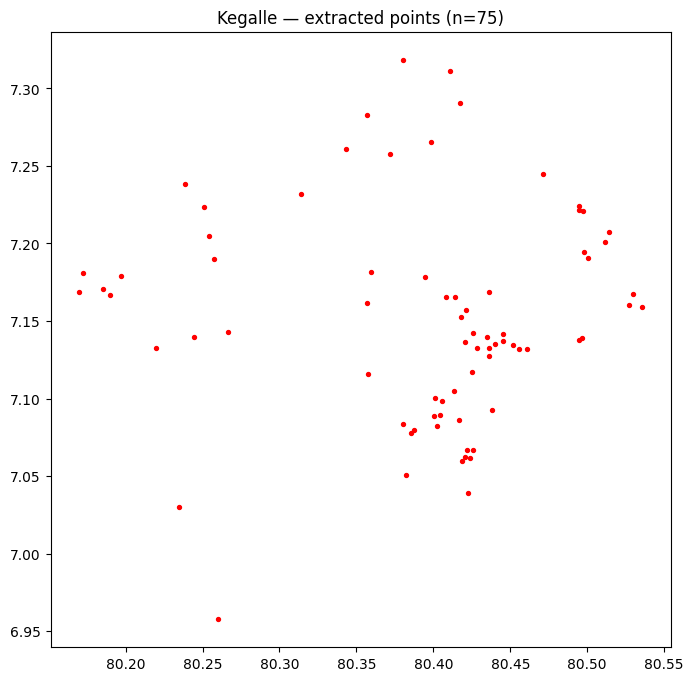

In [20]:
fig, ax = plt.subplots(figsize=(8,8))
gdf.plot(ax=ax, color="red", markersize=8)
ax.set_title(f"{MAP_NAME.capitalize()} — extracted points (n={len(gdf)})")
plt.show()


In [21]:
# ----- CHANGE PER MAP: read the total from the map's own DSD table -----
PRINTED_TOTAL = 77#
# -------------------------------------------------------------------------

match_pct = len(gdf) / PRINTED_TOTAL * 100
print(f"Detected: {len(gdf)} / Printed total: {PRINTED_TOTAL} ({match_pct:.1f}% match)")

Detected: 75 / Printed total: 77 (97.4% match)


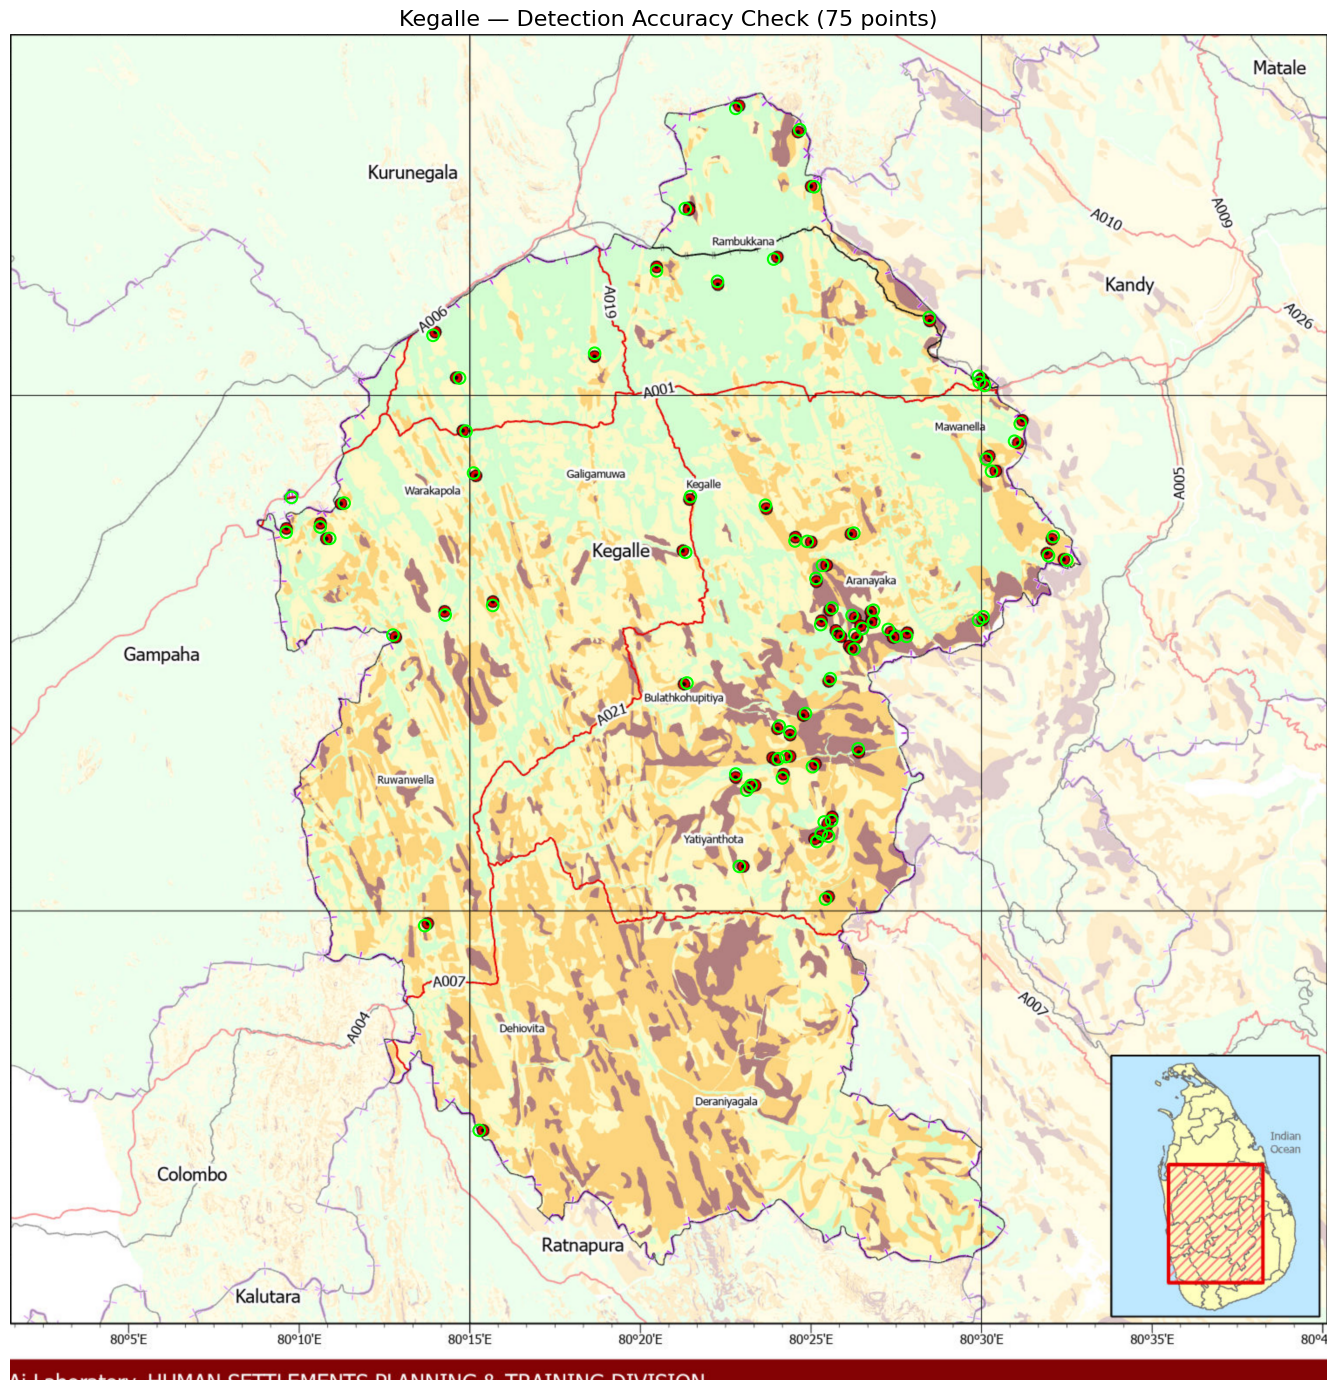

In [22]:
# Visual QA: overlay detected points on original NBRO map
# Circles are drawn in image-pixel (data) coordinates, sized to match
# the actual dot radius calibrated from SINGLE_DOT_AREA, so they scale
# correctly no matter how far you zoom in.

import numpy as np
import matplotlib.patches as mpatches
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(14, 14))

ax.imshow(arr)

# radius (in px) of a single dot, from area = pi * r^2
dot_radius_px = np.sqrt(SINGLE_DOT_AREA / np.pi)

circles = [
    mpatches.Circle((x, y), radius=dot_radius_px * 1.3)  # slight margin so the ring is visible around the dot
    for x, y in points_px
]

ax.add_collection(
    PatchCollection(
        circles,
        facecolor="none",
        edgecolor="lime",
        linewidths=1.5
    )
)

ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MAX, Y_MIN)  # image Y axis runs downward

ax.set_title(
    f"{MAP_NAME.capitalize()} — Detection Accuracy Check ({len(points_px)} points)",
    fontsize=16
)

ax.axis("off")
plt.tight_layout()
plt.show()


In [23]:
import pandas as pd

rows = []
for i, (px, py) in enumerate(points_px, start=1):
    lon, lat = px_to_lonlat(px, py)
    rows.append({
        "id": i,
        "longitude": lon,
        "latitude": lat,
        "area_name": MAP_NAME.capitalize(),
        "pixel_x": px,
        "pixel_y": py
    })

df = pd.DataFrame(rows)
df.to_csv(DATA_PROCESSED /"Kegalle_landslide_points.csv", index=False)
print(f"Saved {len(df)} points to Kegalle_landslide_points.csv")

Saved 75 points to Kegalle_landslide_points.csv


### Part-02 Training table

In [ ]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import rasterio
import matplotlib.pyplot as plt

from shapely.geometry import Point

In [26]:
#  load your extracted Kegalle landslide CSV

csv_path = DATA_PROCESSED / "Kegalle_landslide_points.csv"

assert csv_path.exists(), f"File not found: {csv_path}"

df = pd.read_csv(csv_path)

print(f"Rows loaded: {len(df)}")
print("Columns:", df.columns.tolist())

display(df.head())

Rows loaded: 75
Columns: ['id', 'longitude', 'latitude', 'area_name', 'pixel_x', 'pixel_y']


,id,longitude,latitude,area_name,pixel_x,pixel_y
0,1,80.380520,7.318562,Kegalle,1836.0,447.0
1,2,80.410574,7.311023,Kegalle,1983.0,496.0
2,3,80.417321,7.290866,Kegalle,2016.0,627.0
3,4,80.356804,7.283173,Kegalle,1720.0,677.0
4,5,80.398307,7.265325,Kegalle,1923.0,793.0


In [27]:
#  convert CSV coordinates to GeoDataFrame

Kegalle_pts=gpd.GeoDataFrame(
    df.copy(),
    geometry=gpd.points_from_xy(
        df["longitude"],
        df["latitude"]
    ),
    crs="EPSG:4326"
)

# Convert to the same UTM CRS used by the Sri Lanka rasters
Kegalle_utm = Kegalle_pts.to_crs("EPSG:32644")

# Landslide class
Kegalle_utm["label"] = 1

print(f"{len(Kegalle_utm)} landslide points loaded")
print("CRS:", Kegalle_utm.crs)

display(
    Kegalle_utm[
        ["id", "longitude", "latitude", "area_name", "label", "geometry"]
    ].head()
)

75 landslide points loaded
CRS: EPSG:32644


,id,longitude,latitude,area_name,label,geometry
0,1,80.380520,7.318562,Kegalle,1,POINT (431623.965 809012.117)
1,2,80.410574,7.311023,Kegalle,1,POINT (434940.238 808174.152)
2,3,80.417321,7.290866,Kegalle,1,POINT (435682.082 805944.833)
3,4,80.356804,7.283173,Kegalle,1,POINT (429000.586 805103.379)
4,5,80.398307,7.265325,Kegalle,1,POINT (433579.46 803123.869)


In [28]:
# check that extracted points fall inside Kandy

aoi_path = DATA_PROCESSED / "aoi.gpkg"

aoi = gpd.read_file(
    aoi_path,
    layer="districts"
)

# Select Kegalle
Kegalle_boundary=aoi[
    aoi["adm2_name"].astype(str).str.strip().str.lower() == "kegalle"
].copy()

assert len(Kegalle_boundary) > 0, "Kegalle district not found in AOI"

# IMPORTANT: convert boundary to same CRS as landslide points
Kegalle_utm = Kegalle_utm.to_crs("EPSG:32644")

# Merge Kegalle polygon parts
try:
    Kegalle_poly=Kegalle_boundary.geometry.union_all()
except AttributeError:
    Kegalle_poly = Kegalle_boundary.unary_union

# Check points
within_kegalle = Kegalle_utm.geometry.within(Kegalle_poly)

print(
    f"{within_kegalle.sum()} / {len(Kegalle_utm)} "
    "points fall inside Kegalle district"
)

# Keep only valid Kegalle points
Kegalle_utm = (
    Kegalle_utm[within_kegalle]
    .copy()
    .reset_index(drop=True)
)

print(f"Final landslide points: {len(Kegalle_utm)}")

73 / 75 points fall inside Kegalle district
Final landslide points: 73


In [29]:
# generate matching non-landslide points

BUFFER_METERS = 500
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

# Create exclusion area around known landslides
try:
    buffer_union = Kegalle_utm.geometry.buffer(BUFFER_METERS).union_all()
except AttributeError:
    buffer_union = Kegalle_utm.geometry.buffer(BUFFER_METERS).unary_union

# Valid negative sampling area
valid_area = Kegalle_poly.difference(buffer_union)

assert not valid_area.is_empty, "No valid area available for negative sampling"

minx, miny, maxx, maxy = valid_area.bounds

n_needed = len(Kegalle_utm)

negatives = []
attempts = 0
max_attempts = max(10000, n_needed * 1000)

while len(negatives) < n_needed and attempts < max_attempts:

    pt = Point(
        rng.uniform(minx, maxx),
        rng.uniform(miny, maxy)
    )

    if valid_area.contains(pt):
        negatives.append(pt)

    attempts += 1


neg_gdf = gpd.GeoDataFrame(
    {
        "label": [0] * len(negatives)
    },
    geometry=negatives,
    crs="EPSG:32644"
)

print(f"Landslide points:     {len(Kegalle_utm)}")
print(f"Non-landslide points: {len(neg_gdf)}")
print(f"Sampling attempts:    {attempts}")

Landslide points:     73
Non-landslide points: 73
Sampling attempts:    119


In [30]:
#  combine positive and negative Kegalle samples

positive_gdf = Kegalle_utm[
    ["geometry", "label"]
].copy()

combined = pd.concat(
    [
        positive_gdf,
        neg_gdf[["geometry", "label"]]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs="EPSG:32644"
)

print("Total Kegalle samples:", len(combined))

print("\nClass distribution:")
print(combined["label"].value_counts())

Total Kegalle samples: 146

Class distribution:
label
1    73
0    73
Name: count, dtype: int64


In [31]:
# raster sampling helper

def sample_raster_at_points(raster_path, points_gdf, band=1):

    with rasterio.open(raster_path) as src:

        pts = points_gdf.to_crs(src.crs)

        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        values = np.array(
            [v[band - 1] for v in src.sample(coords)],
            dtype="float64"
        )

        # Convert NoData to NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        return values

In [32]:
#sample existing Sri Lanka terrain rasters

raster_map = {
    "slope": "slope.tif",
    "aspect": "aspect.tif",
    "twi": "twi.tif",
    "spi": "spi.tif",
    "dist_to_river": "dist_to_river.tif",
    "dist_to_road": "dist_to_road.tif",
    "elev": "dem_utm.tif",
    "plan_curv": "plan_curvature.tif",
    "profile_curv": "profile_curvature.tif",
}

available_features = []

for name, fname in raster_map.items():

    path = DATA_PROCESSED / fname

    if path.exists():

        combined[name] = sample_raster_at_points(
            path,
            combined
        )

        available_features.append(name)

        print(f"{name}: sampled")

    else:
        print(f"{name}: MISSING — {fname}")

slope: sampled
aspect: sampled
twi: sampled
spi: sampled
dist_to_river: sampled
dist_to_road: sampled
elev: sampled
plan_curv: sampled
profile_curv: sampled


In [33]:
# metadata and cleaning

combined["country"] = "Sri Lanka"
combined["source_dataset"] = "NBRO_Kegalle_MapExtraction"
combined["district"] = "Kegalle"

# Replace infinite terrain values
combined[available_features] = combined[
    available_features
].replace(
    [np.inf, -np.inf],
    np.nan
)

print("Missing raster values:")
print(combined[available_features].isna().sum())

combined_clean = combined.dropna(
    subset=available_features
).copy()

print(
    f"\nClean Kegalle rows: "
    f"{len(combined_clean)} / {len(combined)}"
)

Missing raster values:
slope            0
aspect           0
twi              0
spi              0
dist_to_river    0
dist_to_road     0
elev             0
plan_curv        0
profile_curv     0
dtype: int64

Clean Kegalle rows: 146 / 146


In [34]:
# ============================================================
# KEGALLE ONLY — FINAL TRAINING TABLE
# No COOLR data
# ============================================================

shared_cols = [
    "geometry",
    "label",
    "country",
    "source_dataset",
    "district",
] + available_features


# Keep only Kegalle data
kegalle_all = combined_clean[
    shared_cols
].copy()


# Ensure GeoDataFrame
kegalle_all = gpd.GeoDataFrame(
    kegalle_all,
    geometry="geometry",
    crs="EPSG:32644"
)


print(
    f"Total Kegalle samples: "
    f"{len(kegalle_all)}"
)

display(
    kegalle_all
    .groupby(["source_dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

Total Kegalle samples: 146


label,0,1
source_dataset,,
NBRO_Kegalle_MapExtraction,73,73


In [35]:
# ============================================================
# SAVE Kegalle PARQUET
# ============================================================

parquet_path = (
    DATA_PROCESSED /
    "training_table_kegalle.parquet"
)

kegalle_all.to_parquet(
    parquet_path,
    index=False
)

print("Saved:", parquet_path)

Saved: ..\data\processed\training_table_kegalle.parquet


In [36]:
# ============================================================
# SAVE Kegalle CSV
# ============================================================

csv_output = kegalle_all.copy()


# UTM coordinates — metres, EPSG:32644
csv_output["x"] = csv_output.geometry.x
csv_output["y"] = csv_output.geometry.y


# Convert to longitude / latitude
wgs84 = csv_output.to_crs(
    "EPSG:4326"
)

csv_output["longitude"] = (
    wgs84.geometry.x
)

csv_output["latitude"] = (
    wgs84.geometry.y
)


# Remove geometry object for CSV
csv_output = pd.DataFrame(
    csv_output.drop(
        columns="geometry"
    )
)


# Save
csv_out_path = (
    DATA_PROCESSED /
    "training_table_kegalle.csv"
)

csv_output.to_csv(
    csv_out_path,
    index=False
)       



print("Saved:", csv_out_path)
print("Shape:", csv_output.shape)

display(csv_output.head())

Saved: ..\data\processed\training_table_kegalle.csv
Shape: (146, 17)


,label,country,source_dataset,district,slope,aspect,twi,spi,dist_to_river,dist_to_road,elev,plan_curv,profile_curv,x,y,longitude,latitude
0,1,Sri Lanka,NBRO_Kegalle_MapExtraction,Kegalle,1.140457,233.698074,3.916666,0.019907,514.587402,43.413120,91.989388,0.086967,0.001692,431623.964844,809012.117129,80.380520,7.318562
1,1,Sri Lanka,NBRO_Kegalle_MapExtraction,Kegalle,6.170734,301.095551,6.943031,12.109214,2489.544678,30.697712,165.693512,-0.033245,-0.000657,434940.237811,808174.152449,80.410574,7.311023
2,1,Sri Lanka,NBRO_Kegalle_MapExtraction,Kegalle,7.368083,282.440155,3.837295,0.775865,350.007751,0.000000,134.441620,-0.008034,-0.000005,435682.082457,805944.833276,80.417321,7.290866
3,1,Sri Lanka,NBRO_Kegalle_MapExtraction,Kegalle,2.945295,166.744431,9.536618,36.684155,3043.411377,543.097961,170.393265,0.025127,-0.006227,429000.585921,805103.378874,80.356804,7.283173
4,1,Sri Lanka,NBRO_Kegalle_MapExtraction,Kegalle,4.666602,209.911469,3.604193,0.244884,796.958923,30.697712,155.669357,-0.008713,-0.002519,433579.460085,803123.869336,80.398307,7.265325
